<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/Customer_Churn_final_project_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv("/content/Customer_Churn_Prediction.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

*Prblem statement:**
The main objective of this project is to develop a Machine Learning model that predicts whether a customer is likely to leave a telecommunications company based on their demographic information, subscribed services, contract details, and payment behavior.

The goal is to help the company identify customers who are at risk of leaving, allowing it to take proactive actions to improve customer retention and reduce customer churn. **bold text**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df['TotalCharges'].value_counts().head(10)

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
19.65,8
19.55,7
45.3,7
20.15,6


In [ ]:
#check null after removing spaces
df['TotalCharges'].str.strip().eq('').sum()

np.int64(11)

In [ ]:
df[df['TotalCharges'].str.strip() == '']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


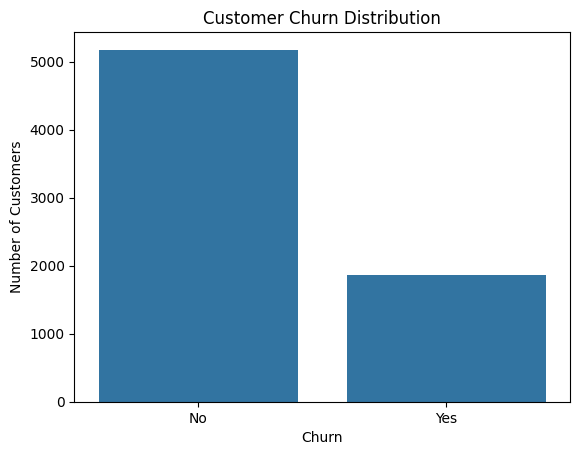

In [ ]:
# Data Visualizzation
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

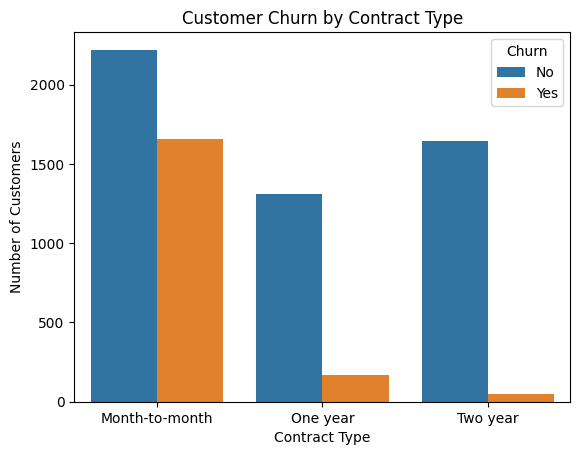

In [ ]:
# churn vs contract type
sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


Customer churn is strongly associated with contract type. Customers with month-to-month contracts have the highest churn rate (42.71%), while customers with one-year contracts have a lower churn rate (11.27%). Customers with two-year contracts have the lowest churn rate (2.83%). This indicates that longer-term contracts are associated with higher customer retention.


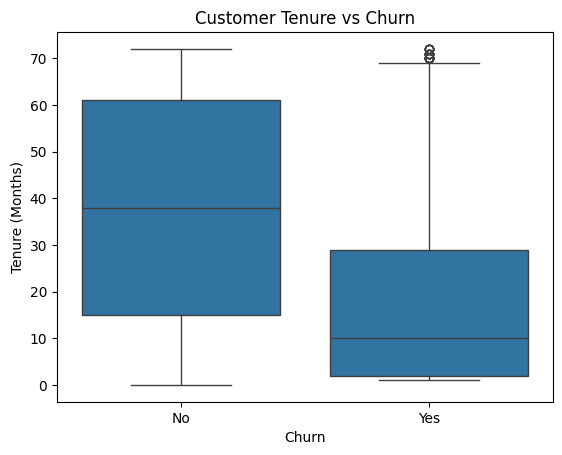

In [ ]:
# tenure vs churn
sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

EDA Finding – Tenure vs Churn

Customers who left the company generally had shorter tenure periods, mostly between 0 and 25 months. In contrast, customers who stayed with the company tended to have longer tenure periods, extending approximately from 15 to 60 months. This suggests that customer tenure is an important feature associated with customer churn.

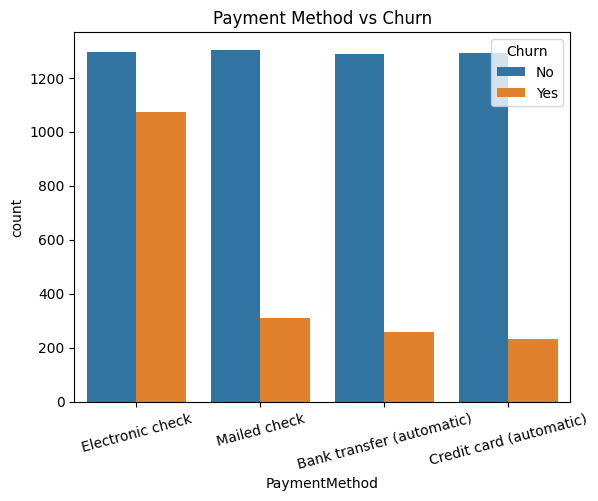

In [ ]:
# churn vs internet service
sns.countplot(data=df, x='PaymentMethod', hue='Churn')

plt.title('Payment Method vs Churn')
plt.xticks(rotation=15)
plt.show()

In [ ]:
pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


EDA Finding – Payment Method vs Churn

Customers using electronic checks have the highest churn rate (45.29%) compared to other payment methods. In contrast, customers using automatic bank transfers and credit cards have lower churn rates. This suggests that payment method is an important feature associated with customer churn.

In [ ]:
# Transform black to nan in total chage column
import numpy as np

df['TotalCharges'] = df['TotalCharges'].str.strip().replace('', np.nan)

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [ ]:
# replace nan values with zeros
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [ ]:
# convert type of totalcharge column from object to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])
df['TotalCharges'].dtype

dtype('float64')

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# drop customer id
df.drop('customerID', axis=1, inplace=True)
df.shape


(7043, 20)

Data splitting

In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [ ]:
# split columns types tp perform encoding
categorical_features = X_train.select_dtypes(include='object').columns.tolist()

numerical_features = X_train.select_dtypes(exclude='object').columns.tolist()

In [ ]:
#encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [ ]:
#feature_names after encoding
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No internet service'
 'cat__StreamingMovies_Yes' 'cat__Contract_Month-to-month'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__PaperlessBi

In [ ]:
#mutual information
from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import numpy as np
from scipy.sparse import issparse

X_train_dense = (
    X_train_processed.toarray()
    if issparse(X_train_processed)
    else X_train_processed
)

discrete_features = np.array([
    name.startswith('cat__') for name in feature_names
])

mi_scores = mutual_info_classif(
    X_train_dense,
    y_train,
    discrete_features=discrete_features,
    random_state=42
)

mi_results = pd.DataFrame({
    'Feature': feature_names,
    'MI Score': mi_scores
})

mi_results = mi_results.sort_values(
    by='MI Score',
    ascending=False
)

print(mi_results)

                                         Feature  MI Score
32                  cat__Contract_Month-to-month  0.092590
42                                   num__tenure  0.071004
14                        cat__OnlineSecurity_No  0.062810
34                        cat__Contract_Two year  0.060477
23                           cat__TechSupport_No  0.059904
43                           num__MonthlyCharges  0.053713
12              cat__InternetService_Fiber optic  0.049318
39           cat__PaymentMethod_Electronic check  0.046062
44                             num__TotalCharges  0.039454
17                          cat__OnlineBackup_No  0.036288
15       cat__OnlineSecurity_No internet service  0.031754
30      cat__StreamingMovies_No internet service  0.031754
27          cat__StreamingTV_No internet service  0.031754
18         cat__OnlineBackup_No internet service  0.031754
24          cat__TechSupport_No internet service  0.031754
21     cat__DeviceProtection_No internet service  0.0317

In [ ]:
#pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

In [ ]:
#model fitting
logistic_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [ ]:
#log pip pred
y_pred = logistic_pipeline.predict(X_test)

In [ ]:
# evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred, pos_label='Yes'))

print("Recall:", recall_score(y_test, y_pred, pos_label='Yes'))

print("F1 Score:", f1_score(y_test, y_pred, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664

Classification Report:

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



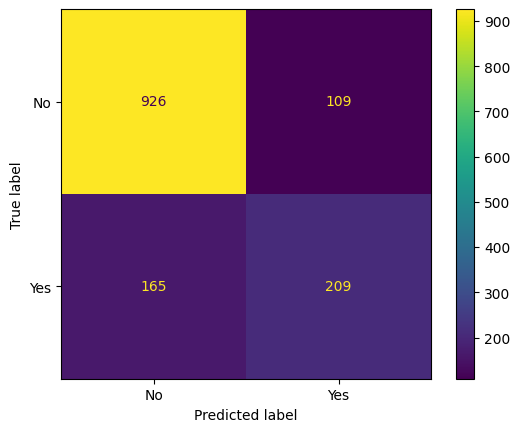

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot()
plt.show()

In [ ]:
logistic_balanced = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

logistic_balanced.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
y_pred_balanced = logistic_balanced.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_balanced, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_balanced, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262

Classification Report:

              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



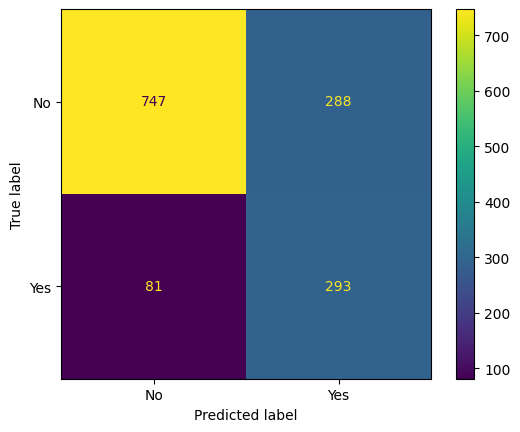

In [ ]:
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=['No', 'Yes']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=['No', 'Yes']
)

disp.plot()
plt.show()

knn model

In [ ]:
#pipeline
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

In [ ]:
knn_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', KNeighborsClassifier())])

In [ ]:
y_pred_knn = knn_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_knn, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_knn, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.7636621717530163
Precision: 0.5526992287917738
Recall: 0.5748663101604278
F1 Score: 0.563564875491481

Classification Report:

              precision    recall  f1-score   support

          No       0.84      0.83      0.84      1035
         Yes       0.55      0.57      0.56       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.76      0.77      1409



decision tree classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

In [ ]:
dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', DecisionTreeClassifier(random_state=42))])

In [ ]:
y_pred_dt = dt_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_dt, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_dt, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.7224982256919801
Precision: 0.4781491002570694
Recall: 0.49732620320855614
F1 Score: 0.4875491480996068

Classification Report:

              precision    recall  f1-score   support

          No       0.82      0.80      0.81      1035
         Yes       0.48      0.50      0.49       374

    accuracy                           0.72      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.72      0.72      1409



random forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [ ]:
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', RandomForestClassifier(random_state=42))])

In [ ]:
y_pred_rf = rf_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_rf, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_rf, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.7877927608232789
Precision: 0.6279863481228669
Recall: 0.4919786096256685
F1 Score: 0.5517241379310345

Classification Report:

              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



SVM MODEL

In [ ]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    ))
])

In [ ]:
svm_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', SVC())])

In [ ]:
y_pred_svm = svm_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_svm, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_svm, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.7913413768630234
Precision: 0.6418439716312057
Recall: 0.4839572192513369
F1 Score: 0.551829268292683

Classification Report:

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



NAIVE BIAS

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GaussianNB())
])

In [ ]:
nb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', GaussianNB())])

In [ ]:
y_pred_nb = nb_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_nb, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_nb, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_nb))

Accuracy: 0.694819020581973
Precision: 0.45894428152492667
Recall: 0.8368983957219251
F1 Score: 0.5928030303030303

Classification Report:

              precision    recall  f1-score   support

          No       0.92      0.64      0.76      1035
         Yes       0.46      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409



GRADIANT BOOSTING

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

In [ ]:
gb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', GradientBoostingClassifier(random_state=42))])

In [ ]:
y_pred_gb = gb_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_gb, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_gb, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_gb))

Accuracy: 0.8026969481902059
Precision: 0.6655172413793103
Recall: 0.516042780748663
F1 Score: 0.5813253012048193

Classification Report:

              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



ADABOOST CASSIFIER

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

In [ ]:
ada_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model',
                 AdaBoostClassifier(learning_rate=0.1, n_estimators=100,
                                    random_state=42))])

In [ ]:
y_pred_ada = ada_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Precision:", precision_score(y_test, y_pred_ada, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_ada, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_ada, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_ada))

Accuracy: 0.7955997161107168
Precision: 0.680672268907563
Recall: 0.43315508021390375
F1 Score: 0.5294117647058824

Classification Report:

              precision    recall  f1-score   support

          No       0.82      0.93      0.87      1035
         Yes       0.68      0.43      0.53       374

    accuracy                           0.80      1409
   macro avg       0.75      0.68      0.70      1409
weighted avg       0.78      0.80      0.78      1409



EXTRA TREES

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

extra_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', ExtraTreesClassifier(
        n_estimators=100,
        random_state=42
    ))
])

extra_pipeline.fit(X_train, y_train)

y_pred_extra = extra_pipeline.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_extra))
print("Precision:", precision_score(y_test, y_pred_extra, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_extra, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred_extra, pos_label='Yes'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_extra))

Accuracy: 0.765791341376863
Precision: 0.5705128205128205
Recall: 0.47593582887700536
F1 Score: 0.5189504373177842

Classification Report:

              precision    recall  f1-score   support

          No       0.82      0.87      0.85      1035
         Yes       0.57      0.48      0.52       374

    accuracy                           0.77      1409
   macro avg       0.70      0.67      0.68      1409
weighted avg       0.75      0.77      0.76      1409



NEW PLANNNNNN

In [ ]:
#SPLIT DATA
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

In [ ]:
#cross validation
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
#scoring
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

In [ ]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, pos_label='Yes'),
    'recall': make_scorer(recall_score, pos_label='Yes'),
    'f1': make_scorer(f1_score, pos_label='Yes')
}

In [ ]:
#models w pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Balanced Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'KNN': KNeighborsClassifier(n_neighbors=5),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale'),

    'Naive Bayes': GaussianNB(),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [ ]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

In [ ]:
#models comparison w cross validation
import pandas as pd

cv_results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by='F1 Score',
    ascending=False
)

print(cv_results_df.round(4))

                          Model  Accuracy  Precision  Recall  F1 Score
1  Balanced Logistic Regression    0.7451     0.5129  0.8013    0.6252
0           Logistic Regression    0.8056     0.6597  0.5525    0.6013
6                   Naive Bayes    0.6974     0.4617  0.8421    0.5963
7             Gradient Boosting    0.8014     0.6576  0.5244    0.5835
5                           SVM    0.7989     0.6653  0.4870    0.5622
4                 Random Forest    0.7847     0.6214  0.4823    0.5427
2                           KNN    0.7590     0.5480  0.5237    0.5352
9                   Extra Trees    0.7634     0.5669  0.4589    0.5067
3                 Decision Tree    0.7297     0.4904  0.4977    0.4936
8                      AdaBoost    0.7884     0.6977  0.3619    0.4758


In [ ]:
#feature selection
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import FunctionTransformer
from scipy.sparse import issparse

def to_dense(X):
    if issparse(X):
        return X.toarray()
    return X

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

fs_models = {
    'Balanced Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000
    ),

    'Naive Bayes': GaussianNB()
}

fs_pipelines = {}

for name, model in fs_models.items():

    fs_pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('dense', FunctionTransformer(to_dense, validate=False)),
        ('selector', SelectKBest(score_func=f_classif)),
        ('model', model)
    ])

In [ ]:
f1_yes = make_scorer(f1_score, pos_label='Yes')

In [ ]:
scoring='f1'

In [ ]:
scoring=f1_yes

In [ ]:
from sklearn.metrics import make_scorer, f1_score

f1_yes = make_scorer(f1_score, pos_label='Yes')

In [ ]:
#GRIDSEARCHCV
from sklearn.model_selection import GridSearchCV
import pandas as pd

k_values = [10, 20, 30, 'all']

fs_results = []
best_fs_models = {}

for name, pipeline in fs_pipelines.items():

    param_grid = {
        'selector__k': k_values
    }

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring=f1_yes,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_fs_models[name] = grid.best_estimator_

    fs_results.append({
        'Model': name,
        'Best Number of Features': grid.best_params_['selector__k'],
        'Best F1 Score': grid.best_score_
    })

fs_results_df = pd.DataFrame(fs_results)

print(fs_results_df.sort_values(
    by='Best F1 Score',
    ascending=False
).round(4))

                          Model Best Number of Features  Best F1 Score
0  Balanced Logistic Regression                     all         0.6252
2                   Naive Bayes                      10         0.6068
1           Logistic Regression                     all         0.6013


In [ ]:
balanced_lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

param_grid_lr = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs']
}

grid_lr = GridSearchCV(
    estimator=balanced_lr_pipeline,
    param_grid=param_grid_lr,
    cv=cv,
    scoring=f1_yes,
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'MultipleLines',
                                                                          'InternetService',
                                                                          'OnlineSecurity',
                                                                          'OnlineBackup',
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'Streaming...
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod']),
                                                                        ('num',
                                                                         StandardScaler(),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges'])])),
                                       ('model',
                                        LogisticRegression(class_weight='balanced',
                                                           max_iter=1000))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                         'model__solver': ['liblinear', 'lbfgs']},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes))

In [ ]:
# MODEL SELECTION
final_model = grid_lr.best_estimator_

In [ ]:
import joblib

joblib.dump(final_model, 'churn_model.pkl')

['churn_model.pkl']

In [ ]:
model = joblib.load('churn_model.pkl')

In [ ]:
y_pred = final_model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred, pos_label='Yes'))

Accuracy: 0.7558552164655784
Precision: 0.5267857142857143
Recall: 0.7887700534759359
F1 Score: 0.6316916488222698


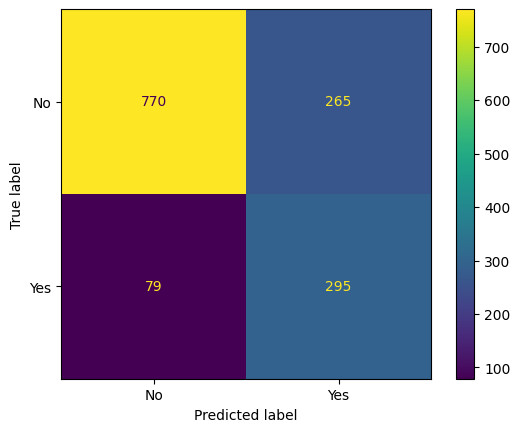

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.91      0.74      0.82      1035
         Yes       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.76      0.77      1409



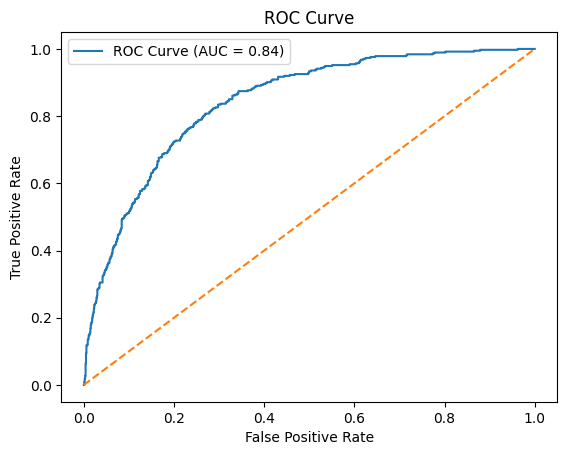

ROC-AUC: 0.8414606422279057


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = final_model.predict_proba(X_test)[:, 1]

y_test_binary = (y_test == 'Yes').astype(int)

fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)

roc_auc = roc_auc_score(y_test_binary, y_prob)

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

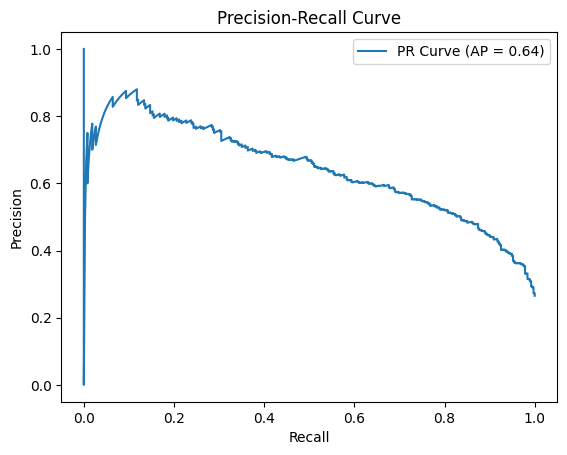

Average Precision: 0.6430030946884382


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test_binary, y_prob
)

ap = average_precision_score(y_test_binary, y_prob)

plt.plot(recall, precision, label=f'PR Curve (AP = {ap:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

print("Average Precision:", ap)

DEPLOYMENT

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import joblib
import os
print(os.listdir())
model = joblib.load('churn_model.pkl')

['.config', 'Customer_Churn_Prediction.csv', '.gradio', 'churn_model.pkl', 'sample_data']


In [ ]:
import pandas as pd

def predict_churn(
    gender, senior, partner, dependents, tenure,
    phone, multiple_lines, internet, security,
    backup, protection, tech_support, streaming_tv,
    streaming_movies, contract, paperless, payment,
    monthly, total
):

    data = pd.DataFrame([{
        'gender': gender,
        'SeniorCitizen': int(senior),
        'Partner': partner,
        'Dependents': dependents,
        'tenure': int(tenure),
        'PhoneService': phone,
        'MultipleLines': multiple_lines,
        'InternetService': internet,
        'OnlineSecurity': security,
        'OnlineBackup': backup,
        'DeviceProtection': protection,
        'TechSupport': tech_support,
        'StreamingTV': streaming_tv,
        'StreamingMovies': streaming_movies,
        'Contract': contract,
        'PaperlessBilling': paperless,
        'PaymentMethod': payment,
        'MonthlyCharges': float(monthly),
        'TotalCharges': float(total)
    }])

    prediction = model.predict(data)[0]
    probability = model.predict_proba(data)[0][
        list(model.classes_).index('Yes')
    ]

    if prediction == 'Yes':
        result = "Customer is likely to leave the company."
    else:
        result = "Customer is likely to stay with the company."

    return f"{result}\nChurn Probability: {probability:.2%}"


inputs = [
    gr.Dropdown(['Female', 'Male'], label='Gender'),
    gr.Dropdown([0, 1], label='Senior Citizen'),
    gr.Dropdown(['Yes', 'No'], label='Partner'),
    gr.Dropdown(['Yes', 'No'], label='Dependents'),
    gr.Number(value=12, label='Tenure (Months)', precision=0),
    gr.Dropdown(['Yes', 'No'], label='Phone Service'),
    gr.Dropdown(['Yes', 'No', 'No phone service'], label='Multiple Lines'),
    gr.Dropdown(['DSL', 'Fiber optic', 'No'], label='Internet Service'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Online Security'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Online Backup'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Device Protection'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Tech Support'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Streaming TV'),
    gr.Dropdown(['Yes', 'No', 'No internet service'], label='Streaming Movies'),
    gr.Dropdown(['Month-to-month', 'One year', 'Two year'], label='Contract'),
    gr.Dropdown(['Yes', 'No'], label='Paperless Billing'),
    gr.Dropdown([
        'Electronic check',
        'Mailed check',
        'Bank transfer (automatic)',
        'Credit card (automatic)'
    ], label='Payment Method'),
    gr.Number(value=70, label='Monthly Charges'),
    gr.Number(value=800, label='Total Charges')
]

app = gr.Interface(
    fn=predict_churn,
    inputs=inputs,
    outputs=gr.Textbox(label='Prediction Result'),
    title='Telco Customer Churn Prediction',
    description='Enter customer information to predict churn.'
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4ed8e3dc1790ed7f89.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
